# Modelo temporal de Oslo — Proyecto 2

## 1. Introducción metodológica
Preparar perfiles mensuales de recursos **relativos y modelados** para integrar posteriormente con el paisaje espacial y el forrajeo. Se leen los dos TXT Dryad y las salidas espaciales locales; no se modifican sus contenidos ni notebooks posteriores.

La ventana directa es corta: julio e inicios de agosto. [Davey et al., Urban Ecosystems, DOI: 10.1007/s11252-023-01458-1](https://doi.org/10.1007/s11252-023-01458-1) documentan muestreo quincenal de polen entre junio y septiembre de 2017, cambios de composición estacional y un único inventario floral por sitio. Sus métodos fechan los inventarios entre 18/07 y 04/08 y las observaciones de visitas entre 18/07 y 10/08 de 2017.

**Interpretación propia:** esta evidencia justifica la temporada June–September y el contexto de año de las fechas florales incompletas; no identifica una curva de abundancia mensual. Composición de polen utilizado, flores disponibles y néctar no son variables intercambiables. Julio tiene el mayor respaldo relativo; agosto, respaldo parcial; junio y septiembre requieren rangos de modelado. Ningún mes se considera automáticamente observado por completo.

Referencias y decisiones están documentadas en `data/project2/sources_temporal.md`; los archivos [Dryad, DOI: 10.5061/dryad.9kd51c5qk](https://doi.org/10.5061/dryad.9kd51c5qk) permanecen intactos. Este notebook funciona sin consultas de red.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import geopandas as gpd
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/project2/raw/oslo/floral_density_data_dryad_version.txt").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abra el notebook desde la raíz del repositorio o un subdirectorio.")
INPUTS = {
    "flora": Path("data/project2/raw/oslo/floral_density_data_dryad_version.txt"),
    "visitas": Path("data/project2/raw/oslo/floral_visitation_data_dryad_version.txt"),
    "spatial_patches": Path("data/project2/processed/spatial_patches.csv"),
    "oslo_parks": Path("data/project2/processed/oslo_parks.geojson")}
for path in INPUTS.values():
    if not (ROOT / path).is_file():
        raise FileNotFoundError(f"Entrada indispensable ausente: {path}. Ejecute primero la etapa espacial.")
OUT = ROOT / "data/project2/processed"
YEAR = 2017
MONTH_NUMBERS = [6, 7, 8, 9]
MONTH_NAMES = {6: "June", 7: "July", 8: "August", 9: "September"}
SEASON_START, SEASON_END = pd.Timestamp(YEAR, 6, 1), pd.Timestamp(YEAR, 9, 30)
SEED = 2017
# Parámetro de demostración, NO una volatilidad estimada para Oslo.
NOISE_SIGMA = 0.15
# Criterio descriptivo conservador de cobertura; no equivale a potencia estadística.
MIN_CALENDAR_DAY_SHARE = 0.50
MIN_TRAPS_PER_DATASET = 10
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.max_columns", 28)
pd.set_option("display.max_colwidth", 95)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")
input_fingerprints = pd.DataFrame([{"input": name, "ruta": str(path), "bytes": (ROOT / path).stat().st_size,
                                   "sha256": hashlib.sha256((ROOT / path).read_bytes()).hexdigest()}
                                  for name, path in INPUTS.items()])
display(input_fingerprints)

Python 3.10.11 | pandas 2.3.3 | numpy 2.2.6 | matplotlib 3.10.9


,input,ruta,bytes,sha256
0,flora,data\project2\raw\oslo\floral_density_data_dryad_version.txt,25499,7750a3be81229e57a8052136e2a46f1599c5e1c33d654e9e050b82979039bd53
1,visitas,data\project2\raw\oslo\floral_visitation_data_dryad_version.txt,127330,71813660a8ade147a46c4dbc42803be5f127b9e8611f300eac1374dd7da15bb1
2,spatial_patches,data\project2\processed\spatial_patches.csv,294268,2145b59ed04aeee9e4611a7e81b6cf5afd6d94f757180af9490e0a378d45e757
3,oslo_parks,data\project2\processed\oslo_parks.geojson,5547696,b1e37b09373c5b0e0cfca4c44ea7f8263c00d52648310e80c59dca560e9bd33d


## 2. Carga y limpieza temporal
Se intenta UTF-8 y luego Windows-1252, con tabulaciones y `NA`/`N/A`/vacíos como ausencias. Se conservan duplicados potenciales para ser consistente con la auditoría; se reporta su sensibilidad posteriormente. Se recortan espacios, sin fusionar nombres taxonómicos.

Se detecta la columna de fecha por nombre. Se conserva `date_explicit` exclusivamente para fechas con año; `date` añade el año **contextualizado por el estudio** solo a fechas parciales válidas. `year_inferred=True` identifica esa decisión; no es una fecha completamente observada. Esto extiende explícitamente el tratamiento conservador de `01_data_audit.ipynb`, que dejó esas fechas completas como `NaT`. Una fecha inexistente o inválida permanece ausente, nunca se sustituye por una fecha vecina.

In [2]:
def load_dryad(path):
    for encoding in ("utf-8-sig", "cp1252"):
        try:
            result = pd.read_csv(path, sep="\t", encoding=encoding,
                                 na_values=["NA", "N/A", ""], on_bad_lines="error")
            print(path.name, "|", encoding, "|", result.shape)
            return result
        except UnicodeDecodeError:
            continue
    raise UnicodeError(f"No se pudo interpretar {path.name} sin reemplazar caracteres.")

def detect_date_column(frame):
    names = [c for c in frame if c.casefold() in {"inventory_date", "date", "sampling_date"}]
    if len(names) != 1:
        raise ValueError(f"Columna de fecha ausente o ambigua: {names}")
    return names[0]

def parse_dates(series, context_year):
    text = series.astype("string").str.strip().str.lower()
    explicit = pd.to_datetime(text, format="%d.%m.%Y", errors="coerce")
    tokens = text.str.extract(r"^(\d{1,2})\.(jul|aug)(?:\.(\d{2}|\d{4}))?$")
    day = pd.to_numeric(tokens[0], errors="coerce").astype("Int64").astype("string")
    month = tokens[1].map({"jul": "07", "aug": "08"}).astype("string")
    suffix = tokens[2]
    written_year = suffix.where(suffix.str.len().eq(4), "20" + suffix)
    spelled_complete = pd.to_datetime(written_year + "-" + month + "-" + day, format="%Y-%m-%d", errors="coerce")
    explicit = explicit.fillna(spelled_complete)
    partial = tokens[0].notna() & suffix.isna()
    contextual = pd.to_datetime(str(context_year) + "-" + month + "-" + day, format="%Y-%m-%d", errors="coerce")
    inferred = explicit.isna() & partial & contextual.notna()
    date = explicit.where(~inferred, contextual)
    status = pd.Series("inválida", index=text.index, dtype="string")
    status.loc[text.isna()] = "ausente"
    status.loc[explicit.notna()] = "año explícito"
    status.loc[inferred] = "año contextualizado por publicación"
    return pd.DataFrame({"date_explicit": explicit, "date": date,
                         "year_inferred": inferred, "date_status": status})

raw = {name: load_dryad(ROOT / INPUTS[name]) for name in ["flora", "visitas"]}
data, temporal_rows = {}, []
NUMERIC = ["flower_number", "transect_width_cm", "transect_length_m", "individuals_flying",
           "individuals_sitting", "temperature_C", "sky_cover"]
for label, original in raw.items():
    print(f"\n{label}: duplicados exactos adicionales conservados = {int(original.duplicated().sum())}")
    df = original.copy()
    for col in df.select_dtypes(include=["object", "string"]):
        df[col] = df[col].astype("string").str.strip().replace("", pd.NA)
    for col in [x for x in NUMERIC if x in df]:
        converted = pd.to_numeric(df[col], errors="coerce")
        invalid = df[col].notna() & converted.isna()
        if invalid.any():
            print(col, "valores no numéricos convertidos a ausencia:", int(invalid.sum()))
        df[col] = converted
    date_col = detect_date_column(df)
    print("Columna de fecha detectada:", date_col)
    parsed = parse_dates(df[date_col], YEAR)
    for col in parsed:
        df[col] = parsed[col]
    df["month_number"] = df.date.dt.month.astype("Int64")
    if df.date.dropna().dt.year.ne(YEAR).any():
        raise ValueError("Apareció un año distinto de la temporada configurada; revisar contexto.")
    display(df.date_status.value_counts().rename("registros").to_frame())
    print("Rango SOLO con año explícito:", df.date_explicit.min(), "a", df.date_explicit.max())
    print("Rango contextualizado para análisis:", df.date.min(), "a", df.date.max())
    if df.date.isna().any():
        display(df.loc[df.date.isna(), [date_col, "date_status", "trap_number"]])
    daily = df.dropna(subset=["date"]).groupby("date").agg(
        registros=(date_col, "size"), traps=("trap_number", "nunique"),
        registros_con_año_contextualizado=("year_inferred", "sum"))
    display(daily)
    temporal_rows.append({"dataset": label, "fecha_min": df.date.min(), "fecha_max": df.date.max(),
                          "dias_unicos": df.date.nunique(), "registros": len(df), "traps_unicos": df.trap_number.nunique(),
                          "registros_fechados": df.date.notna().sum(), "fechas_ausentes_invalidas": df.date.isna().sum(),
                          "registros_año_contextualizado": df.year_inferred.sum()})
    data[label] = df
flora, visitas = data["flora"], data["visitas"]
temporal_summary = pd.DataFrame(temporal_rows)
display(temporal_summary)

floral_density_data_dryad_version.txt | utf-8-sig | (593, 7)
floral_visitation_data_dryad_version.txt | cp1252 | (1297, 16)

flora: duplicados exactos adicionales conservados = 4
Columna de fecha detectada: inventory_date


,registros
date_status,
año contextualizado por publicación,577
año explícito,16


Rango SOLO con año explícito: 2017-08-02 00:00:00 a 2017-08-02 00:00:00
Rango contextualizado para análisis: 2017-07-18 00:00:00 a 2017-08-04 00:00:00


,registros,traps,registros_con_año_contextualizado
date,,,
2017-07-18,17,4,17
2017-07-19,39,8,39
2017-07-21,10,2,10
2017-07-22,77,18,77
2017-07-24,33,7,33
2017-07-25,55,10,55
2017-07-26,108,7,108
2017-07-27,51,9,51
2017-07-28,30,5,30



visitas: duplicados exactos adicionales conservados = 6
Columna de fecha detectada: inventory_date


,registros
date_status,
año explícito,1296
ausente,1


Rango SOLO con año explícito: 2017-07-18 00:00:00 a 2017-08-10 00:00:00
Rango contextualizado para análisis: 2017-07-18 00:00:00 a 2017-08-10 00:00:00


,inventory_date,date_status,trap_number
1154,<NA>,ausente,195


,registros,traps,registros_con_año_contextualizado
date,,,
2017-07-18,20,4,0
2017-07-19,49,7,0
2017-07-20,123,23,0
2017-07-21,61,14,0
2017-07-22,97,19,0
2017-07-23,40,9,0
2017-07-24,43,9,0
2017-07-25,48,10,0
2017-07-26,113,16,0


,dataset,fecha_min,fecha_max,dias_unicos,registros,traps_unicos,registros_fechados,fechas_ausentes_invalidas,registros_año_contextualizado
0,flora,2017-07-18,2017-08-04,12,593,100,593,0,577
1,visitas,2017-07-18,2017-08-10,20,1297,101,1296,1,0


## 3. Cobertura observacional
El gráfico conserva todo junio–septiembre; los días sin registros son **sin muestreo conocido**, no cero flores o cero actividad.

`direct_observation` es un criterio conservador de suficiencia descriptiva mensual: ambos archivos deben cubrir al menos la mitad de los días del mes y al menos 10 traps cada uno. Los umbrales son configurables, elegidos para no llamar «mensual» a unos pocos días; no son una prueba de representatividad ni de potencia estadística. Se reportan días y traps para no depender únicamente de esa bandera.

`has_direct_records`/`is_directly_observed_period` indican solo presencia de registros de ambos tipos en una parte del mes. No significan observación completa del mes ni de cada parque GIS.

,month,floral_records,visitation_records,direct_observation,has_direct_records,floral_days,visitation_days,floral_traps,visitation_traps,floral_day_share,visitation_day_share
0,June,0,0,False,False,0,0,0,0,0.000000,0.000000
1,July,420,911,False,True,9,14,70,76,0.290323,0.451613
2,August,173,385,False,True,3,6,30,34,0.096774,0.193548
3,September,0,0,False,False,0,0,0,0,0.000000,0.000000


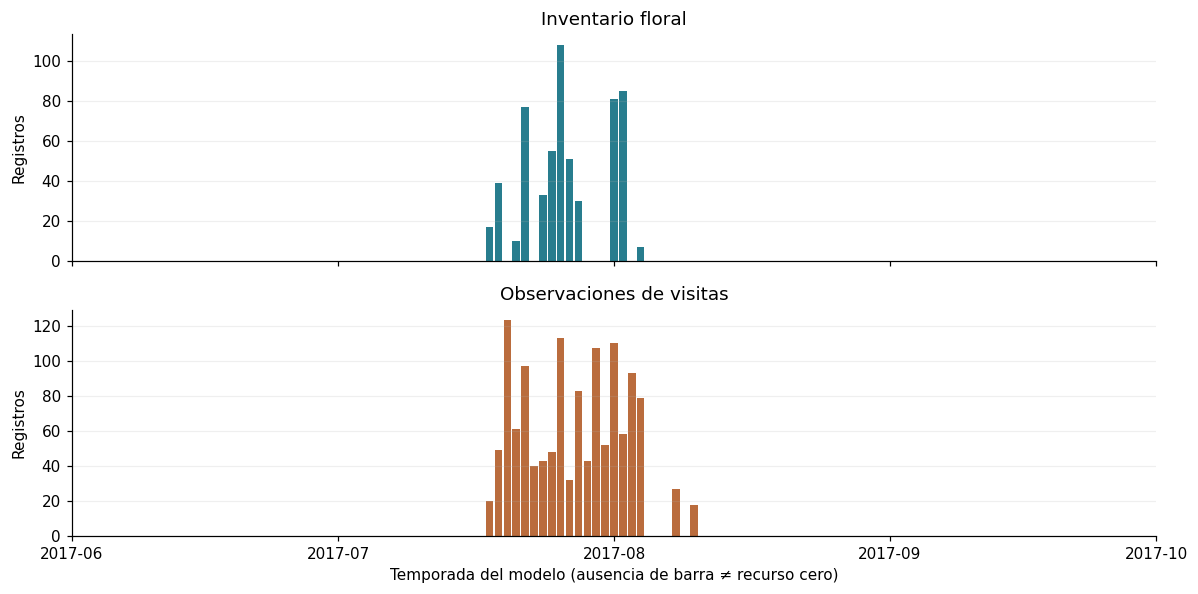

In [3]:
calendar = pd.DataFrame({"month_number": MONTH_NUMBERS})
calendar["month"] = calendar.month_number.map(MONTH_NAMES)
calendar["month_start"] = pd.to_datetime(dict(year=YEAR, month=calendar.month_number, day=1))
calendar["calendar_days"] = calendar.month_start.dt.days_in_month
coverage = calendar.copy()
for label, frame in [("floral", flora), ("visitation", visitas)]:
    grouped = frame.dropna(subset=["date"]).groupby("month_number").agg(
        records=("date", "size"), days=("date", "nunique"), traps=("trap_number", "nunique"))
    for col in ["records", "days", "traps"]:
        coverage[f"{label}_{col}"] = coverage.month_number.map(grouped[col]).fillna(0).astype(int)
    coverage[f"{label}_day_share"] = coverage[f"{label}_days"] / coverage.calendar_days
coverage["has_direct_records"] = coverage.floral_records.gt(0) & coverage.visitation_records.gt(0)
coverage["direct_observation"] = (coverage.floral_day_share.ge(MIN_CALENDAR_DAY_SHARE)
                                   & coverage.visitation_day_share.ge(MIN_CALENDAR_DAY_SHARE)
                                   & coverage.floral_traps.ge(MIN_TRAPS_PER_DATASET)
                                   & coverage.visitation_traps.ge(MIN_TRAPS_PER_DATASET))
display(coverage[["month", "floral_records", "visitation_records", "direct_observation", "has_direct_records",
                  "floral_days", "visitation_days", "floral_traps", "visitation_traps",
                  "floral_day_share", "visitation_day_share"]])

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, (label, frame, color) in zip(axes, [("Inventario floral", flora, "#287D8E"),
                                         ("Observaciones de visitas", visitas, "#BA6C3D")]):
    counts = frame.dropna(subset=["date"]).groupby("date").size()
    ax.bar(counts.index, counts.values, width=.85, color=color)
    ax.set(ylabel="Registros", title=label)
    ax.set_xlim(SEASON_START, SEASON_END + pd.Timedelta(days=1))
    ax.grid(axis="y", alpha=.2)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[-1].set_xlabel("Temporada del modelo (ausencia de barra ≠ recurso cero)")
fig.tight_layout()
plt.show()

## 4. Densidad floral por fecha y especie
Se reconstruye `flowers_per_m2_record = flower_number / (transect_width_cm / 100 × transect_length_m)`, exactamente como en la auditoría. Se preservan los 14 valores florales fraccionarios y el conteo ausente; no se redondean ni imputan. Solo se admiten dimensiones positivas. Los percentiles describen la muestra, no intervalos de confianza de una curva estacional.

Se muestra además una densidad total por sitio/fecha: suma de las contribuciones taxonómicas por m², comprobando que ancho y largo sean constantes dentro del grupo. El área no se suma de nuevo por especie. Un sitio con todos los conteos ausentes queda ausente, no cero. Los 100 sitios se inventariaron una sola vez: **fecha, composición y localización están confundidas**. No se ajusta una tendencia causal o longitudinal.

Áreas no positivas/ausentes: 0 | conteos negativos: 0
Conteos florales fraccionarios: 14


,n,mean,median,std,p10,p25,p75,p90,traps
date,,,,,,,,,
2017-07-18,17,8.847059,3.0000,14.766516,0.1250,0.625000,12.87500,20.200000,4
2017-07-19,38,1.855263,0.7500,2.691846,0.1250,0.375000,2.18750,5.112500,8
2017-07-21,10,5.625000,2.9375,7.287022,0.2375,1.187500,7.59375,10.312500,2
2017-07-22,77,3.009064,0.8750,5.144651,0.2000,0.479167,2.50000,9.150000,18
2017-07-24,33,2.839015,1.0625,4.217391,0.1250,0.375000,3.25000,8.275000,7
2017-07-25,55,2.184659,0.6250,3.560379,0.1250,0.250000,2.18750,6.650000,10
2017-07-26,108,2.252315,0.5000,4.789249,0.0000,0.125000,2.00000,6.500000,7
2017-07-27,51,2.384804,0.2500,7.555951,0.1250,0.125000,1.12500,6.250000,9
2017-07-28,30,4.776389,0.8750,9.139704,0.1250,0.250000,4.56250,9.875000,5


Fechas florales por sitio: {1: 100}


,n,mean,median,std,p10,p25,p75,p90
date,,,,,,,,
2017-07-18,4,37.600000,22.31250,40.074831,11.037500,13.343750,46.568750,76.392500
2017-07-19,7,10.071429,10.50000,4.631734,4.583333,7.937500,12.583333,14.200000
2017-07-21,2,28.125000,28.12500,21.920310,15.725000,20.375000,35.875000,40.525000
2017-07-22,18,12.872106,11.18750,8.858656,2.687500,5.992188,17.375000,27.018750
2017-07-24,7,13.383929,7.87500,14.631873,2.300000,4.625000,17.781250,31.837500
2017-07-25,10,12.015625,8.78125,11.055899,0.450000,5.812500,14.656250,28.946875
2017-07-26,7,34.750000,28.00000,30.696345,6.600000,12.625000,52.062500,76.500000
2017-07-27,9,13.513889,7.37500,19.887422,0.500000,2.000000,16.500000,27.875000
2017-07-28,5,28.658333,13.25000,41.202154,5.175000,12.000000,15.791667,67.291667


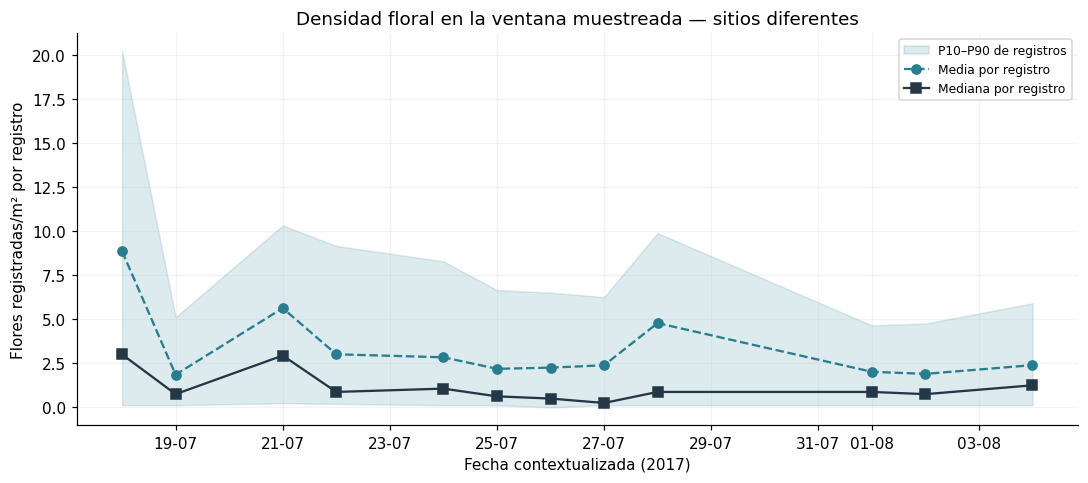

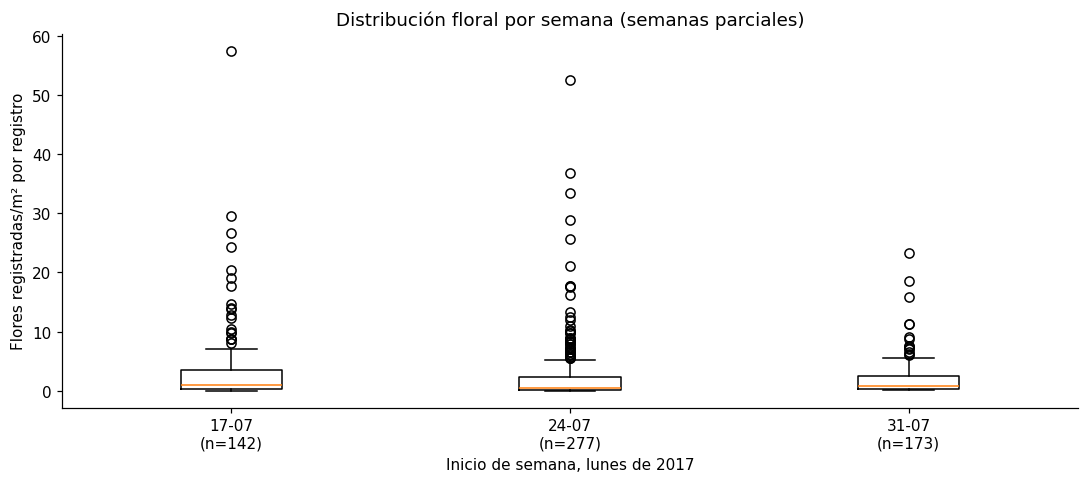

In [4]:
required_floral = ["flower_number", "transect_width_cm", "transect_length_m", "plant_species_latin_name", "trap_number"]
missing = sorted(set(required_floral) - set(flora))
if missing:
    raise ValueError(f"Faltan variables indispensables para el indicador floral: {missing}")
area = flora.transect_width_cm / 100 * flora.transect_length_m
valid_area = flora.transect_width_cm.gt(0) & flora.transect_length_m.gt(0)
flora["transect_area_m2"] = area.where(valid_area)
flora["flowers_per_m2_record"] = flora.flower_number.where(flora.flower_number.ge(0)) / flora.transect_area_m2
print("Áreas no positivas/ausentes:", int((~valid_area).sum()), "| conteos negativos:", int(flora.flower_number.lt(0).sum()))
print("Conteos florales fraccionarios:", int((flora.flower_number.notna() & flora.flower_number.mod(1).ne(0)).sum()))

def distribution_summary(grouped):
    return grouped.agg(n="count", mean="mean", median="median", std="std",
                       p10=lambda s: s.quantile(.10), p25=lambda s: s.quantile(.25),
                       p75=lambda s: s.quantile(.75), p90=lambda s: s.quantile(.90))

floral_daily = distribution_summary(flora.dropna(subset=["date"]).groupby("date").flowers_per_m2_record)
floral_daily["traps"] = flora.groupby("date").trap_number.nunique()
display(floral_daily)
keys = ["trap_number", "date"]
dimensions = flora.dropna(subset=["date"]).groupby(keys)[["transect_width_cm", "transect_length_m"]].nunique()
if dimensions.gt(1).any().any():
    raise ValueError("Dimensiones incompatibles dentro de trap/fecha: no agregar como un solo transecto.")
site_flora = flora.dropna(subset=["date"]).groupby(keys).agg(
    density=("flowers_per_m2_record", lambda s: s.sum(min_count=1)),
    taxon_records=("flowers_per_m2_record", "size"), valid_records=("flowers_per_m2_record", "count")) .reset_index()
site_flora["month_number"] = site_flora.date.dt.month
visits_per_site = site_flora.groupby("trap_number").date.nunique()
print("Fechas florales por sitio:", visits_per_site.value_counts().to_dict())
display(distribution_summary(site_flora.groupby("date").density))

fig, ax = plt.subplots()
ax.fill_between(floral_daily.index, floral_daily.p10, floral_daily.p90, color="#287D8E", alpha=.15, label="P10–P90 de registros")
ax.plot(floral_daily.index, floral_daily["mean"], "o--", color="#287D8E", label="Media por registro")
ax.plot(floral_daily.index, floral_daily["median"], "s-", color="#243746", label="Mediana por registro")
ax.set(title="Densidad floral en la ventana muestreada — sitios diferentes", ylabel="Flores registradas/m² por registro", xlabel="Fecha contextualizada (2017)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
ax.grid(alpha=.15)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

flora["week_start"] = flora.date.dt.to_period("W-SUN").dt.start_time
weeks = [(date, group.flowers_per_m2_record.dropna()) for date, group in flora.dropna(subset=["week_start"]).groupby("week_start")]
fig, ax = plt.subplots()
ax.boxplot([values.to_numpy() for _, values in weeks], showfliers=True)
ax.set_xticks(range(1, len(weeks) + 1), [f"{date:%d-%m}\n(n={len(values)})" for date, values in weeks])
ax.set(title="Distribución floral por semana (semanas parciales)", xlabel="Inicio de semana, lunes de 2017", ylabel="Flores registradas/m² por registro")
fig.tight_layout()
plt.show()

count       mean   median     sum
date       plant_species_latin_name                                   
2017-07-18 Aegopodium podagraria         1   0.625000   0.6250   0.625
           Campanula latifolia           1   0.875000   0.8750   0.875
           Epilobium montanum            1   0.125000   0.1250   0.125
           Geum sp.                      1   0.125000   0.1250   0.125
           Hieracium sp.                 1   1.375000   1.3750   1.375
           Lysimachia nummularia         1  12.875000  12.8750  12.875
           Melampyrum                    1  29.500000  29.5000  29.500
           Melilotus sp.                 2   5.512500   5.5125  11.025
           Potentilla sp.                1   0.500000   0.5000   0.500
           Ranunculus acris              1   0.125000   0.1250   0.125
           Trifolium sp.                 3   5.916667   3.0000  17.750
           Tripleurospermum sp.          1  57.500000  57.5000  57.500
           Vicia sp.                     2   9.000000   9.0000  18.000
2017-07-19 Achillea sp.                  1   0.125000   0.1250   0.125
           Alchemilla                    1   0.125000   0.1250   0.125
           Bunias orientalis             1   0.375000   0.3750   0.375
           Campanula latifolia           1   0.500000   0.5000   0.500
           Campanula rapunculoides       2   1.437500   1.4375   2.875
           Chamerion angustifolium       1   0.125000   0.1250   0.125
           Cirsium arvense               2   5.187500   5.1875  10.375

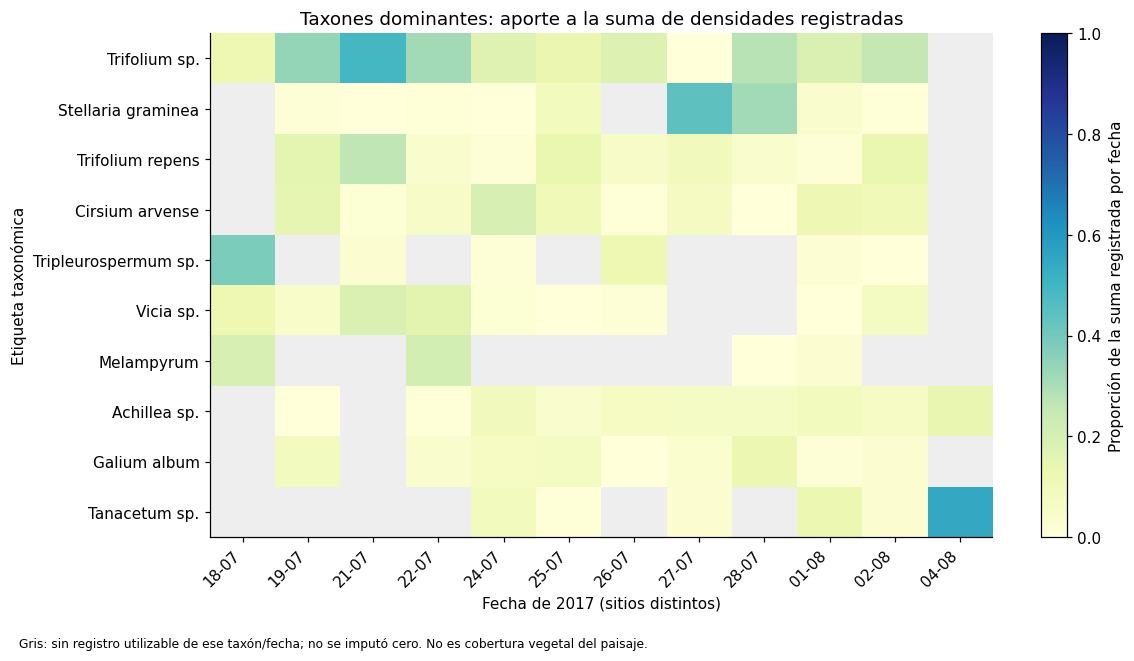

In [5]:
species_daily = flora.dropna(subset=["date", "plant_species_latin_name"]).groupby(
    ["date", "plant_species_latin_name"]).flowers_per_m2_record.agg(["count", "mean", "median", "sum"])
display(species_daily.head(20))
top_species = flora.groupby("plant_species_latin_name").flowers_per_m2_record.sum(min_count=1).nlargest(10).index
contributions = species_daily["sum"].unstack("date").reindex(top_species)
denominator = flora.groupby("date").flowers_per_m2_record.sum(min_count=1)
shares = contributions.div(denominator, axis="columns")
fig, ax = plt.subplots(figsize=(11, 6))
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#EEEEEE")
image = ax.imshow(np.ma.masked_invalid(shares.to_numpy()), aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(shares.columns)), [f"{d:%d-%m}" for d in shares.columns], rotation=45, ha="right")
ax.set_yticks(range(len(shares.index)), shares.index)
ax.set(title="Taxones dominantes: aporte a la suma de densidades registradas", xlabel="Fecha de 2017 (sitios distintos)", ylabel="Etiqueta taxonómica")
fig.colorbar(image, ax=ax, label="Proporción de la suma registrada por fecha")
fig.text(.02, .01, "Gris: sin registro utilizable de ese taxón/fecha; no se imputó cero. No es cobertura vegetal del paisaje.", fontsize=8)
fig.tight_layout(rect=(0, .04, 1, 1))
plt.show()

## 5. Individuos observados y actividad temporal
`individuals_total` suma individuos volando y posados cuando ambos conteos existen. No identifica individuos únicos ni confirma polinización. Se respetan los duplicados potenciales y se muestran conteos por fecha sin confundir esfuerzo de observación con abundancia.

Para `individuals_per_min` se reconstruyen las **sesiones candidatas** de la auditoría: trap, fecha, inicio, fin y observadores disponibles. Se suman individuos por sesión y se divide una sola vez por su duración. Se excluyen las filas sin fecha u horario válido y los intervalos no positivos. Las sesiones carecen de ID independiente y deben validarse. La tasa diaria usa suma de individuos/suma de minutos de esas sesiones, no una suma de tasas de filas. El índice relativo reescala esa tasa por su máximo observado; no es un factor de recursos.

Inicio ausente/no interpretable: 1 | fin: 93 | duración no positiva: 0
Filas fuera de sesiones candidatas: 93
Sesiones candidatas: 218


,trap_number,date,observation_start,observation_end,observer1,observer2,individuals_total,duration_min,records,temperature_C,sky_cover,wind,rain,individuals_per_min
0,101,2017-07-19,10:32,10:49,AK,<NA>,22,17.0,11,16.5,80.0,windy,<NA>,1.294118
1,101,2017-07-21,11:10,11:22,AK,<NA>,4,12.0,4,16.0,100.0,no wind,<NA>,0.333333
2,101,2017-07-29,11:32,11:42,SD,<NA>,16,10.0,9,15.0,80.0,<NA>,some rain,1.600000
3,101,2017-07-31,11:33,11:40,SH,<NA>,3,7.0,2,21.0,80.0,<NA>,<NA>,0.428571
4,102,2017-07-19,14:10,14:30,JS,<NA>,48,20.0,11,17.0,75.0,<NA>,<NA>,2.400000


,individuals_total,observations,traps,session_individuals,observed_minutes,candidate_sessions,individuals_per_min,relative_activity
date,,,,,,,,
2017-07-18,94,20,4,20,37.0,3,0.540541,0.226800
2017-07-19,158,49,7,158,87.0,7,1.816092,0.761997
2017-07-20,352,123,23,340,156.0,21,2.179487,0.914470
2017-07-21,171,61,14,171,112.0,14,1.526786,0.640609
2017-07-22,307,97,19,283,192.0,18,1.473958,0.618444
2017-07-23,148,40,9,143,60.0,7,2.383333,1.000000
2017-07-24,102,43,9,102,119.0,8,0.857143,0.359640
2017-07-25,135,48,10,135,125.0,10,1.080000,0.453147
2017-07-26,276,113,16,261,200.0,15,1.305000,0.547552


observations  individuals
date       pollinator_species_latin                           
2017-07-18 Apis mellifera                       5           41
           Bombus lapidarius                    3           32
           Bombus lucorum Coll.                 2            9
           Bombus pascuorum                     2            2
           Bombus pratorum                      3            3
           Bombus soroeensis                    1            2
           Colletes daviesanus                  1            1
           Lepidoptera                          1            1
           Syrphidae                            2            3
2017-07-19 Apis mellifera                      14           80
           Bombus humilis                       3            3
           Bombus hypnorum                      4            6
           Bombus lapidarius                    6            8
           Bombus lucorum Coll.                 1            1
           Bombus pascuorum                     2            3
           Bombus pratorum                      1            2
           Bombus ruderarius                    1            1
           Bombus soroeensis                    1            1
           Bombus sp.                           2            2
           Bombus terrestris                    1            1

,individuals_total
pollinator_species_latin,
Apis mellifera,1565
Bombus lapidarius,647
Bombus pascuorum,255
Syrphidae,159
Bombus pratorum,152
Bombus lucorum Coll.,148
Bombus sp.,60
Bombus ruderarius,58
Bombus sylvarum,55


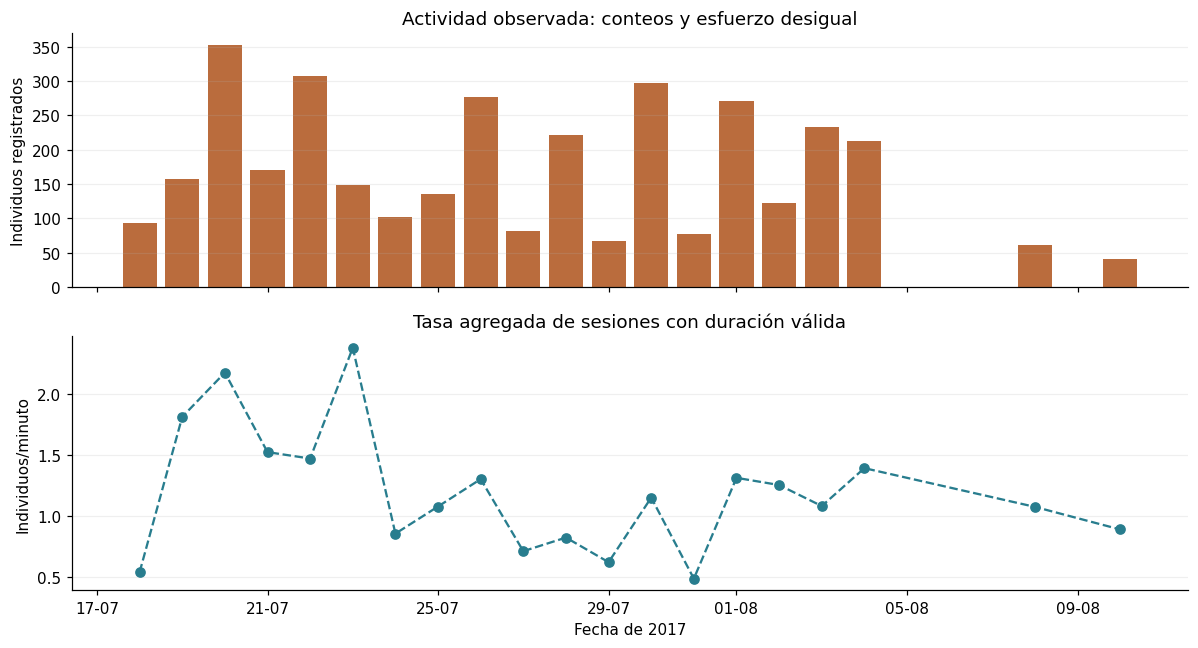

In [6]:
required_visits = ["individuals_flying", "individuals_sitting", "observation_start", "observation_end", "trap_number"]
missing = sorted(set(required_visits) - set(visitas))
if missing:
    raise ValueError(f"Faltan columnas para reconstruir actividad: {missing}")
visitas["individuals_total"] = visitas[["individuals_flying", "individuals_sitting"]].sum(axis=1, min_count=2)
start = pd.to_datetime(visitas.observation_start, format="%H:%M", errors="coerce")
end = pd.to_datetime(visitas.observation_end, format="%H:%M", errors="coerce")
duration = (end - start).dt.total_seconds() / 60
visitas["duration_min"] = duration.where(duration.gt(0))
visitas["individuals_per_min_record"] = visitas.individuals_total / visitas.duration_min
print("Inicio ausente/no interpretable:", int(start.isna().sum()), "| fin:", int(end.isna().sum()), "| duración no positiva:", int(duration.le(0).sum()))
session_keys = ["trap_number", "date", "observation_start", "observation_end"]
valid_session = visitas[session_keys].notna().all(axis=1) & visitas.duration_min.notna()
print("Filas fuera de sesiones candidatas:", int((~valid_session).sum()))
session_keys += [x for x in ["observer1", "observer2"] if x in visitas]
grouped = visitas.loc[valid_session].groupby(session_keys, dropna=False)
sessions = grouped.agg(individuals_total=("individuals_total", lambda s: s.sum(min_count=1)),
                       duration_min=("duration_min", "first"), records=("individuals_total", "size"))
weather_columns = [x for x in ["temperature_C", "sky_cover", "wind", "rain"] if x in visitas]
weather_conflicts = []
for col in weather_columns:
    nvalues = grouped[col].nunique(dropna=True)
    sessions[col] = grouped[col].first().where(nvalues.le(1))
    weather_conflicts.append({"variable": col, "sesiones_discrepantes": int(nvalues.gt(1).sum()),
                              "sesiones_sin_valor_utilizable": int(sessions[col].isna().sum())})
sessions["individuals_per_min"] = sessions.individuals_total / sessions.duration_min
sessions = sessions.reset_index()
print("Sesiones candidatas:", len(sessions))
display(sessions.head())
visitation_daily = visitas.dropna(subset=["date"]).groupby("date").agg(
    individuals_total=("individuals_total", lambda s: s.sum(min_count=1)),
    observations=("individuals_total", "size"), traps=("trap_number", "nunique"))
rates = sessions.groupby("date").agg(session_individuals=("individuals_total", "sum"),
                                    observed_minutes=("duration_min", "sum"), candidate_sessions=("duration_min", "size"))
rates["individuals_per_min"] = rates.session_individuals / rates.observed_minutes
rates["relative_activity"] = rates.individuals_per_min / rates.individuals_per_min.max()
visitation_daily = visitation_daily.join(rates)
display(visitation_daily)
if "pollinator_species_latin" in visitas:
    pollinator_daily = visitas.groupby(["date", "pollinator_species_latin"], dropna=False).agg(
        observations=("individuals_total", "size"), individuals=("individuals_total", lambda s: s.sum(min_count=1)))
    display(pollinator_daily.head(20))
    display(visitas.groupby("pollinator_species_latin", dropna=False).individuals_total.sum(min_count=1).sort_values(ascending=False).to_frame())

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].bar(visitation_daily.index, visitation_daily.individuals_total, color="#BA6C3D", width=.8)
axes[0].set(ylabel="Individuos registrados", title="Actividad observada: conteos y esfuerzo desigual")
axes[1].plot(rates.index, rates.individuals_per_min, "o--", color="#287D8E")
axes[1].set(ylabel="Individuos/minuto", xlabel="Fecha de 2017", title="Tasa agregada de sesiones con duración válida")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

## 6. Clima y actividad: exploración descriptiva
Se usan sesiones candidatas para no replicar un valor meteorológico por cada taxón. Temperatura se expresa en °C; `sky_cover` es la escala registrada, sin asignar una unidad no documentada. Viento y lluvia son categorías textuales; `wet vegetation` no es intensidad de lluvia y una ausencia no significa clima seco o viento cero.

Se muestran tamaños de muestra, Pearson y Spearman cuando existen al menos tres pares válidos con variación, y promedios por condición. No se calculan efectos causales ni se aplican las correlaciones como multiplicadores del modelo: fecha, sitio, observador y duración pueden confundir la asociación.

Variables meteorológicas ausentes: []


,variable,sesiones_discrepantes,sesiones_sin_valor_utilizable
0,temperature_C,0,2
1,sky_cover,0,1
2,wind,0,190
3,rain,0,204


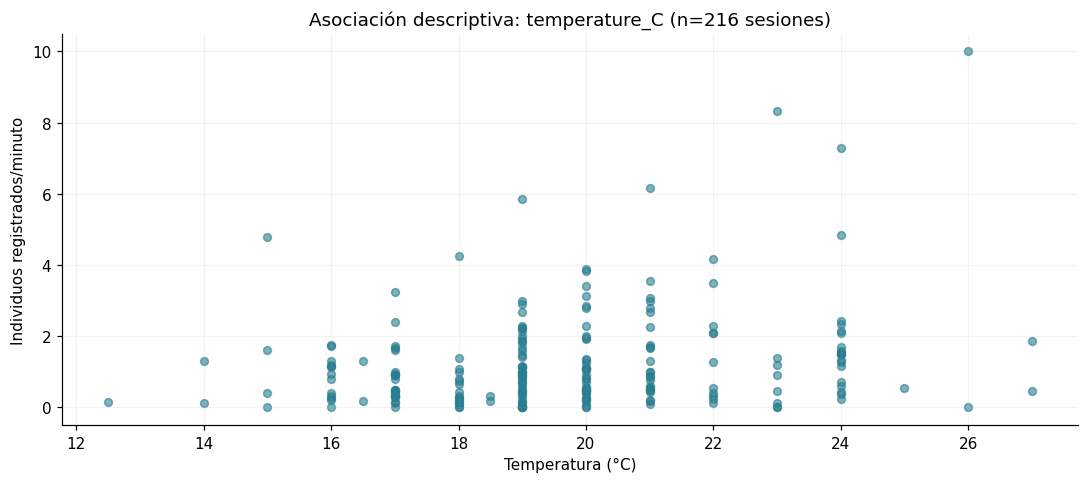

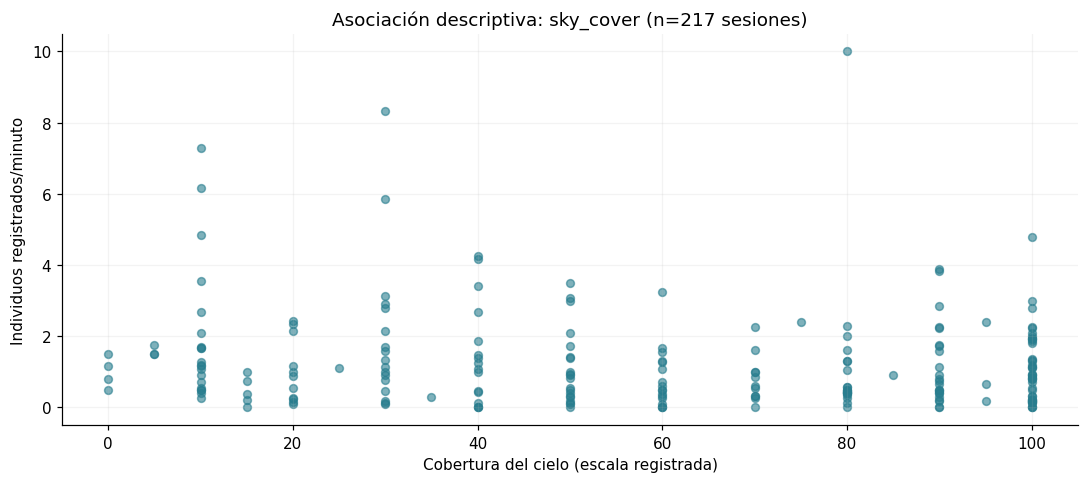

,variable,n_pares,pearson,spearman
0,temperature_C,216,0.243307,0.220059
1,sky_cover,217,-0.124846,-0.107160


,n_sessions,mean_rate,median_rate,individuals,minutes,pooled_rate
wind,,,,,,
no wind,13,0.684978,0.733333,138,186.0,0.741935
windy,15,1.059906,0.700000,233,232.0,1.004310
<NA>,190,1.332369,0.919872,2792,2222.0,1.256526


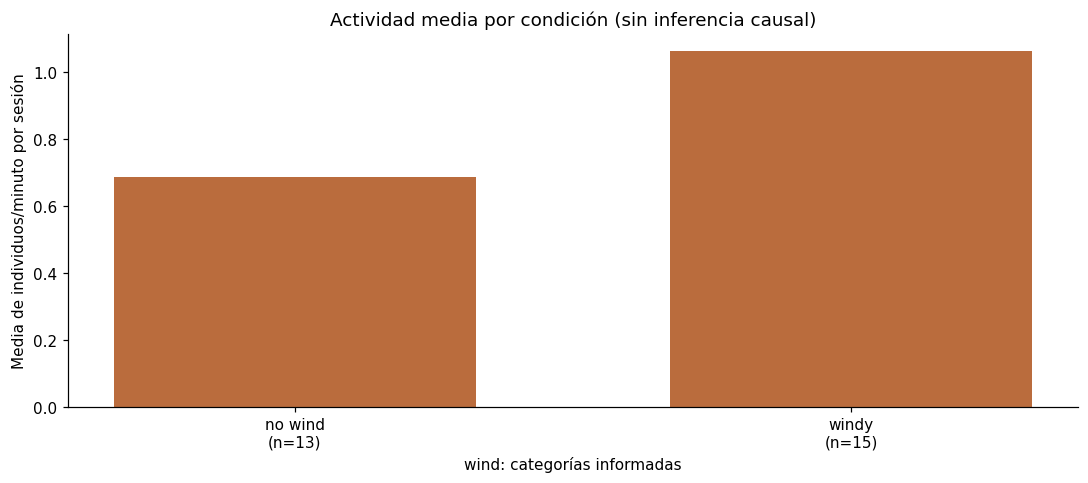

,n_sessions,mean_rate,median_rate,individuals,minutes,pooled_rate
rain,,,,,,
some rain,11,1.315912,1.142857,193,155.0,1.245161
wet vegetation,3,0.827778,0.750000,45,54.0,0.833333
<NA>,204,1.279388,0.912879,2925,2431.0,1.203209


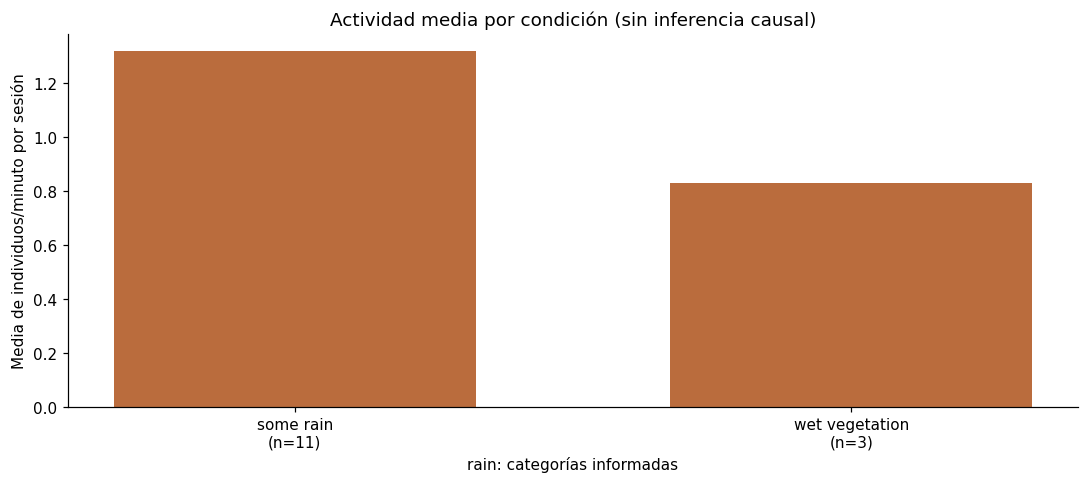

In [7]:
print("Variables meteorológicas ausentes:", sorted(set(["temperature_C", "sky_cover", "wind", "rain"]) - set(weather_columns)))
display(pd.DataFrame(weather_conflicts))
correlations = []
for col in [x for x in ["temperature_C", "sky_cover"] if x in sessions]:
    pairs = sessions[[col, "individuals_per_min"]].dropna()
    usable = len(pairs) >= 3 and pairs.nunique().gt(1).all()
    correlations.append({"variable": col, "n_pares": len(pairs),
                         "pearson": pairs[col].corr(pairs.individuals_per_min) if usable else np.nan,
                         "spearman": pairs[col].corr(pairs.individuals_per_min, method="spearman") if usable else np.nan})
    if not pairs.empty:
        fig, ax = plt.subplots()
        ax.scatter(pairs[col], pairs.individuals_per_min, s=26, alpha=.6, color="#287D8E")
        ax.set(xlabel="Temperatura (°C)" if col == "temperature_C" else "Cobertura del cielo (escala registrada)",
               ylabel="Individuos registrados/minuto", title=f"Asociación descriptiva: {col} (n={len(pairs)} sesiones)")
        ax.grid(alpha=.15)
        fig.tight_layout()
        plt.show()
display(pd.DataFrame(correlations))
for col in [x for x in ["wind", "rain"] if x in sessions]:
    table = sessions.groupby(col, dropna=False).agg(
        n_sessions=("individuals_per_min", "count"), mean_rate=("individuals_per_min", "mean"),
        median_rate=("individuals_per_min", "median"), individuals=("individuals_total", "sum"), minutes=("duration_min", "sum"))
    table["pooled_rate"] = table.individuals / table.minutes
    display(table)
    plot_table = table.loc[table.index.notna()]
    if not plot_table.empty:
        fig, ax = plt.subplots()
        ax.bar(range(len(plot_table)), plot_table.mean_rate, color="#BA6C3D", width=.65)
        ax.set_xticks(range(len(plot_table)), [f"{key}\n(n={int(row.n_sessions)})" for key, row in plot_table.iterrows()])
        ax.set(xlabel=f"{col}: categorías informadas", ylabel="Media de individuos/minuto por sesión", title="Actividad media por condición (sin inferencia causal)")
        fig.tight_layout()
        plt.show()

## 7. Temporada principal del modelo
La primera versión utiliza cuatro pasos mensuales: **June, July, August, September de 2017**. La evidencia quincenal externa respalda estudiar esta temporada, pero **no obliga ni valida una resolución mensual**: agrupar por mes es una simplificación computacional propia. No se resuelven pulsos de floración, reposición diaria o clima entre muestreos.

La tabla siguiente ajusta el nivel de respaldo a la cobertura encontrada: observación de una ventana no equivale a conocer el mes completo. El año contextualizado permanece trazable; los datos originales no fueron modificados.

In [8]:
evidence = coverage[["month_number", "month", "month_start", "has_direct_records", "direct_observation"]].copy()
evidence["evidence_level"] = evidence.apply(
    lambda row: ("Dryad_window_plus_external_seasonality" if row.month_number == 7 else "Dryad_sparse_window_plus_external_seasonality")
    if row.has_direct_records else "external_seasonality_only_no_Dryad_amount", axis=1)
evidence["description"] = evidence.apply(
    lambda row: f"{row.month}: {int(coverage.loc[coverage.month_number.eq(row.month_number), 'floral_days'].iloc[0])} días florales; "
                f"{int(coverage.loc[coverage.month_number.eq(row.month_number), 'visitation_days'].iloc[0])} días de visitas. "
                + ("Cobertura mensual insuficiente según el criterio declarado." if not row.direct_observation else "Supera el criterio descriptivo, sin garantizar representatividad."), axis=1)
display(evidence[["month", "evidence_level", "description"]])

,month,evidence_level,description
0,June,external_seasonality_only_no_Dryad_amount,June: 0 días florales; 0 días de visitas. Cobertura mensual insuficiente según el criterio ...
1,July,Dryad_window_plus_external_seasonality,July: 9 días florales; 14 días de visitas. Cobertura mensual insuficiente según el criterio...
2,August,Dryad_sparse_window_plus_external_seasonality,August: 3 días florales; 6 días de visitas. Cobertura mensual insuficiente según el criteri...
3,September,external_seasonality_only_no_Dryad_amount,September: 0 días florales; 0 días de visitas. Cobertura mensual insuficiente según el crit...


## 8. Perfil normalizado — MODELO provisional con identificación parcial
Se evita inventar una curva completa. El indicador usa la **mediana de densidad total por sitio de cada mes observado**, para dar el mismo peso a cada sitio y reducir la influencia de valores extremos y del número de taxones por fila.

Definición: `reference_density = max(medianas mensuales observadas)` y `floral_factor = min(mediana / reference_density, 1)`. Es un índice saturado respecto de la muestra, **no una fracción del máximo real de toda la temporada**, ni masa de polen, néctar o capacidad del parque. Las contribuciones por m² siguen siendo un indicador provisional de la auditoría.

- Julio y agosto aportan anclas **modeladas a partir de muestras directas**, con sitios distintos; su contraste no demuestra descenso temporal.
- Para los meses muestreados, los límites son P10–P90 de densidades de sitios, normalizados y saturados con la misma referencia: describen **heterogeneidad espacial muestral**, no incertidumbre temporal completa ni intervalos de confianza.
- Junio y septiembre no tienen una estimación puntual: `floral_factor = NaN`, límites `[0, 1]`, el dominio admisible del índice. No se imputa cero, 0.5, una campana fenológica ni un valor leído de una figura. Estos límites no están calibrados y no son una distribución probabilística.

La evidencia estacional externa motiva mantener los cuatro meses y la incertidumbre: cambios de composición no determinan cantidades mensuales. No se interpola ni extrapola fuera de la ventana Dryad; la insuficiencia de evidencia queda en las salidas, como permite la opción de rangos de esta etapa.

,n,mean,median,std,p10,p25,p75,p90
month_number,,,,,,,,
7,69,17.838527,11.2500,21.222782,1.2250,5.65625,19.00000,34.550
8,30,11.384970,8.5625,8.024367,3.7625,6.15625,14.96875,21.825


Referencia muestral (flores registradas/m²): 11.25


,month,floral_factor,floral_factor_lower,floral_factor_upper,evidence_level,factor_status,derivation_method
0,June,NaN,0.000000,1.0,external_seasonality_only_no_Dryad_amount,unidentified_range_only,"No numeric Dryad anchor; external seasonal context only; retain [0,1] without midpoint"
1,July,1.000000,0.108889,1.0,Dryad_window_plus_external_seasonality,modeled_sample_proxy,Median summed density per trap/month divided by observed monthly reference; no temporal ext...
2,August,0.761111,0.334444,1.0,Dryad_sparse_window_plus_external_seasonality,modeled_sample_proxy,Median summed density per trap/month divided by observed monthly reference; no temporal ext...
3,September,NaN,0.000000,1.0,external_seasonality_only_no_Dryad_amount,unidentified_range_only,"No numeric Dryad anchor; external seasonal context only; retain [0,1] without midpoint"


,mediana_sitios_original,mediana_sin_duplicados_exactos
7,11.2500,11.2500
8,8.5625,8.5625


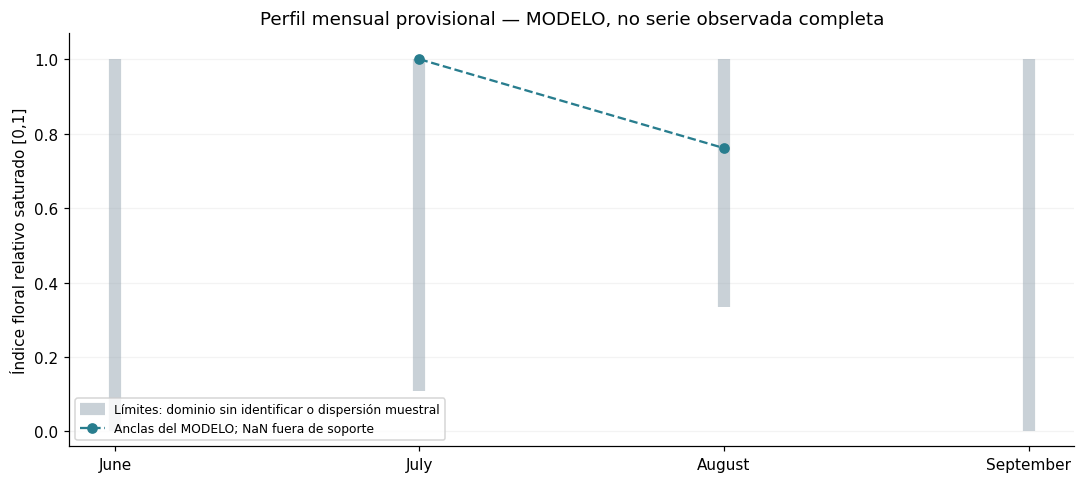

In [9]:
monthly_density = distribution_summary(site_flora.groupby("month_number").density)
reference_density = monthly_density["median"].max()
if not np.isfinite(reference_density) or reference_density <= 0:
    raise ValueError("No hay una referencia floral positiva para normalizar sin inventar datos.")
profile = evidence.copy()
profile["floral_factor"] = profile.month_number.map(monthly_density["median"]) / reference_density
profile["floral_factor"] = profile.floral_factor.clip(0, 1)
profile["floral_factor_lower"] = (profile.month_number.map(monthly_density.p10) / reference_density).clip(0, 1)
profile["floral_factor_upper"] = (profile.month_number.map(monthly_density.p90) / reference_density).clip(0, 1)
unidentified = profile.floral_factor.isna()
profile.loc[unidentified, "floral_factor_lower"] = 0.0
profile.loc[unidentified, "floral_factor_upper"] = 1.0
profile["factor_is_observed"] = False
profile["factor_status"] = np.where(unidentified, "unidentified_range_only", "modeled_sample_proxy")
profile["interval_kind"] = np.where(unidentified, "unidentified_admissible_domain_not_CI", "spatial_sample_p10_p90_saturated_not_CI")
profile["derivation_method"] = np.where(unidentified,
    "No numeric Dryad anchor; external seasonal context only; retain [0,1] without midpoint",
    "Median summed density per trap/month divided by observed monthly reference; no temporal extrapolation")
profile["reference_density_flowers_per_m2"] = reference_density
profile["is_directly_observed_period"] = profile.has_direct_records
profile["monthly_observation_sufficient"] = profile.direct_observation
profile["year"] = YEAR
display(monthly_density)
print("Referencia muestral (flores registradas/m²):", reference_density)
display(profile[["month", "floral_factor", "floral_factor_lower", "floral_factor_upper", "evidence_level", "factor_status", "derivation_method"]])

# Sensibilidad determinista al excluir solo duplicados exactos: no reemplaza el análisis principal.
dedup = flora.loc[~raw["flora"].duplicated()].copy()
dedup_sites = dedup.groupby(["trap_number", "date"]).flowers_per_m2_record.sum(min_count=1).reset_index()
dedup_medians = dedup_sites.groupby(dedup_sites.date.dt.month).flowers_per_m2_record.median()
display(pd.DataFrame({"mediana_sitios_original": monthly_density["median"],
                      "mediana_sin_duplicados_exactos": dedup_medians}))

fig, ax = plt.subplots()
x = np.arange(len(profile))
ax.vlines(x, profile.floral_factor_lower, profile.floral_factor_upper, color="#94A5B0", lw=8, alpha=.5,
          label="Límites: dominio sin identificar o dispersión muestral")
ax.plot(x, profile.floral_factor, "o--", color="#287D8E", label="Anclas del MODELO; NaN fuera de soporte")
ax.set_xticks(x, profile.month)
ax.set(ylim=(-.04, 1.07), ylabel="Índice floral relativo saturado [0,1]", title="Perfil mensual provisional — MODELO, no serie observada completa")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## 9. Variabilidad estocástica preparada
Se propone una perturbación multiplicativa lognormal positiva: `random_variation ~ Lognormal(-sigma²/2, sigma)`. Por construcción su **media teórica es 1**. Es apropiada como primera hipótesis para variaciones proporcionales y evita recursos negativos. `NOISE_SIGMA=0.15` es un parámetro configurable de demostración, **no estimado con los datos**; no se atribuye a Oslo una volatilidad temporal identificada.

Se genera una sola realización de cuatro meses con `default_rng(SEED)`, sin experimentos masivos. Una muestra de cuatro números no garantiza media empírica uno. Se deja un choque general por mes, sin fabricar diferencias entre parques. Los meses sin ancla puntual permanecen ausentes, con límites transformables.

`effective_resource_factor_raw = seasonal_factor × random_variation`; el índice operativo se satura en 1. La saturación mantiene el rango del índice, pero introduce sesgo cerca del techo: no conserva media uno del factor efectivo. No debe interpretarse como conservación de masa o estimación de recursos absolutos.

In [10]:
def temporal_noise(n_months, seed=SEED, sigma=NOISE_SIGMA):
    if sigma < 0 or not np.isfinite(sigma):
        raise ValueError("sigma debe ser finita y no negativa.")
    rng = np.random.default_rng(seed)
    return rng.lognormal(mean=-sigma ** 2 / 2, sigma=sigma, size=n_months)

variation = temporal_noise(len(profile))
stochastic_example = profile[["month", "floral_factor", "floral_factor_lower", "floral_factor_upper"]].copy()
stochastic_example["random_variation"] = variation
stochastic_example["effective_resource_factor_raw"] = stochastic_example.floral_factor * variation
stochastic_example["effective_resource_factor"] = stochastic_example.effective_resource_factor_raw.clip(0, 1)
stochastic_example["effective_lower"] = (stochastic_example.floral_factor_lower * variation).clip(0, 1)
stochastic_example["effective_upper"] = (stochastic_example.floral_factor_upper * variation).clip(0, 1)
print("Seed:", SEED, "| sigma demostrativa:", NOISE_SIGMA,
      "| media teórica:", np.exp(-NOISE_SIGMA ** 2 / 2 + NOISE_SIGMA ** 2 / 2),
      "| media de esta única realización:", variation.mean())
display(stochastic_example)

Seed: 2017 | sigma demostrativa: 0.15 | media teórica: 1.0 | media de esta única realización: 1.0082831214021875


,month,floral_factor,floral_factor_lower,floral_factor_upper,random_variation,effective_resource_factor_raw,effective_resource_factor,effective_lower,effective_upper
0,June,NaN,0.000000,1.0,1.215404,NaN,NaN,0.000000,1.000000
1,July,1.000000,0.108889,1.0,0.907244,0.907244,0.907244,0.098789,0.907244
2,August,0.761111,0.334444,1.0,1.176808,0.895682,0.895682,0.393577,1.000000
3,September,NaN,0.000000,1.0,0.733677,NaN,NaN,0.000000,0.733677


## 10. Integración con los parches espaciales
Se verifican los IDs del CSV frente al GeoJSON y se mantienen **todas** las columnas espaciales, incluidas las restricciones. El producto es una unión cartesiana `patch_id × month`, sin unir arbitrariamente traps y parques. Los mismos factores relativos generales se comparten entre parches; no se multiplica la superficie del parque por densidades de traps sin vínculo espacial.

`seasonal_floral_factor` permanece ausente en junio y septiembre; se exportan sus límites y `factor_status` para que el siguiente notebook no convierta ausencia en cero. `is_directly_observed_period` se refiere a la ventana del conjunto Dryad, **no al parque individual**. `factor_is_observed=False` y `direct_observation_scope` explicitan esa diferencia. Los choques aleatorios son una demostración separada y no se incorporan como si fueran observaciones.

In [11]:
spatial = pd.read_csv(ROOT / INPUTS["spatial_patches"])
parks_geo = gpd.read_file(ROOT / INPUTS["oslo_parks"])
if spatial.patch_id.isna().any() or not spatial.patch_id.is_unique:
    raise ValueError("Los IDs del catálogo espacial deben ser únicos y no nulos.")
if not parks_geo.patch_id.is_unique or set(spatial.patch_id) != set(parks_geo.patch_id):
    raise ValueError("Los IDs del CSV y GeoJSON espaciales no coinciden.")
print("Parques verificados:", len(spatial), "| CRS GeoJSON:", parks_geo.crs)
temporal_general = profile[["month_number", "month", "month_start", "year", "floral_factor", "floral_factor_lower",
    "floral_factor_upper", "evidence_level", "derivation_method", "factor_status", "interval_kind", "factor_is_observed",
    "is_directly_observed_period", "monthly_observation_sufficient", "reference_density_flowers_per_m2"]].rename(
    columns={"floral_factor": "seasonal_floral_factor", "floral_factor_lower": "seasonal_floral_factor_lower",
             "floral_factor_upper": "seasonal_floral_factor_upper"})
temporal_general["direct_observation_scope"] = "pooled_Dryad_window_not_this_GIS_patch"
temporal_patches = spatial.merge(temporal_general, how="cross")
display(temporal_patches.head(8))
print("Filas patch_id × month:", len(temporal_patches))
display(temporal_patches.groupby("month").agg(patch_ids=("patch_id", "nunique"),
    point_factors_available=("seasonal_floral_factor", "count"),
    candidate_patches=("is_initial_candidate", "sum")).reindex(list(MONTH_NAMES.values())))

Parques verificados: 737 | CRS GeoJSON: EPSG:4326


,patch_id,source_object_id,area_m2,centroid_x_m,centroid_y_m,centroid_wkt,analysis_crs,centroid_inside_patch,intersects_restricted_zone,restricted_overlap_m2,restricted_overlap_fraction,is_initial_candidate,candidate_rule,source_url,...,month_start,year,seasonal_floral_factor,seasonal_floral_factor_lower,seasonal_floral_factor_upper,evidence_level,derivation_method,factor_status,interval_kind,factor_is_observed,is_directly_observed_period,monthly_observation_sufficient,reference_density_flowers_per_m2,direct_observation_scope
0,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,1,384.024302,264237.001060,6.644648e+06,POINT (264237.00106 6644648.485151),EPSG:25833,True,True,384.024302,1.0,False,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,...,2017-06-01,2017,NaN,0.000000,1.0,external_seasonality_only_no_Dryad_amount,"No numeric Dryad anchor; external seasonal context only; retain [0,1] without midpoint",unidentified_range_only,unidentified_admissible_domain_not_CI,False,False,False,11.25,pooled_Dryad_window_not_this_GIS_patch
1,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,1,384.024302,264237.001060,6.644648e+06,POINT (264237.00106 6644648.485151),EPSG:25833,True,True,384.024302,1.0,False,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,...,2017-07-01,2017,1.000000,0.108889,1.0,Dryad_window_plus_external_seasonality,Median summed density per trap/month divided by observed monthly reference; no temporal ext...,modeled_sample_proxy,spatial_sample_p10_p90_saturated_not_CI,False,True,False,11.25,pooled_Dryad_window_not_this_GIS_patch
2,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,1,384.024302,264237.001060,6.644648e+06,POINT (264237.00106 6644648.485151),EPSG:25833,True,True,384.024302,1.0,False,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,...,2017-08-01,2017,0.761111,0.334444,1.0,Dryad_sparse_window_plus_external_seasonality,Median summed density per trap/month divided by observed monthly reference; no temporal ext...,modeled_sample_proxy,spatial_sample_p10_p90_saturated_not_CI,False,True,False,11.25,pooled_Dryad_window_not_this_GIS_patch
3,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,1,384.024302,264237.001060,6.644648e+06,POINT (264237.00106 6644648.485151),EPSG:25833,True,True,384.024302,1.0,False,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,...,2017-09-01,2017,NaN,0.000000,1.0,external_seasonality_only_no_Dryad_amount,"No numeric Dryad anchor; external seasonal context only; retain [0,1] without midpoint",unidentified_range_only,unidentified_admissible_domain_not_CI,False,False,False,11.25,pooled_Dryad_window_not_this_GIS_patch
4,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_2,2,664.396977,260730.721895,6.650925e+06,POINT (260730.721895 6650925.342784),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,...,2017-06-01,2017,NaN,0.000000,1.0,external_seasonality_only_no_Dryad_amount,"No numeric Dryad anchor; external seasonal context only; retain [0,1] without midpoint",unidentified_range_only,unidentified_admissible_domain_not_CI,False,False,False,11.25,pooled_Dryad_window_not_this_GIS_patch
5,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_2,2,664.396977,260730.721895,6.650925e+06,POINT (260730.721895 6650925.342784),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,...,2017-07-01,2017,1.000000,0.108889,1.0,Dryad_window_plus_external_seasonality,Median summed density per trap/month divided by observed monthly reference; no temporal ext...,modeled_sa

Filas patch_id × month: 2948


,patch_ids,point_factors_available,candidate_patches
month,,,
June,737,0,375
July,737,737,375
August,737,737,375
September,737,0,375


## 11. Escenarios temporales para sensibilidad
`baseline` conserva el perfil principal, incluidos sus meses sin ancla. `early_flowering` desplaza el perfil **un paso mensual hacia antes**; `late_flowering`, un paso hacia después. El tamaño de paso es una perturbación estructural igual a la resolución de esta primera versión, no una fecha de floración estimada.

Para un mes destino m, early usa la fila fuente m+1 y late usa m−1. Se desplazan conjuntamente punto, límites, estado y evidencia de origen; `factor_source_month_number` deja la correspondencia visible. No se usa `roll` circular: no se recicla septiembre en junio. Si la fuente está fuera de la temporada, el punto queda ausente y se conserva `[0,1]` como dominio no identificado; no se inventa cero en los extremos ni se conserva artificialmente un total estacional.

Las banderas de observación del mes **destino** permanecen ligadas al calendario real. Un factor desplazado a junio o septiembre es un escenario de modelado, aunque provenga de una ancla de julio/agosto. No se lanzan experimentos de simulación.

,scenario,month,factor_source_month_number,floral_factor,floral_factor_lower,floral_factor_upper,evidence_level
0,baseline,June,6,NaN,0.000000,1.0,external_seasonality_only_no_Dryad_amount
1,baseline,July,7,1.000000,0.108889,1.0,Dryad_window_plus_external_seasonality
2,baseline,August,8,0.761111,0.334444,1.0,Dryad_sparse_window_plus_external_seasonality
3,baseline,September,9,NaN,0.000000,1.0,external_seasonality_only_no_Dryad_amount
4,early_flowering,June,7,1.000000,0.108889,1.0,modeled_shift_of_Dryad_window_plus_external_seasonality
5,early_flowering,July,8,0.761111,0.334444,1.0,modeled_shift_of_Dryad_sparse_window_plus_external_seasonality
6,early_flowering,August,9,NaN,0.000000,1.0,modeled_shift_of_external_seasonality_only_no_Dryad_amount
7,early_flowering,September,10,NaN,0.000000,1.0,modeled_shift_boundary_unidentified
8,late_flowering,June,5,NaN,0.000000,1.0,modeled_shift_boundary_unidentified
9,late_flowering,July,6,NaN,0.000000,1.0,modeled_shift_of_external_seasonality_only_no_Dryad_amount


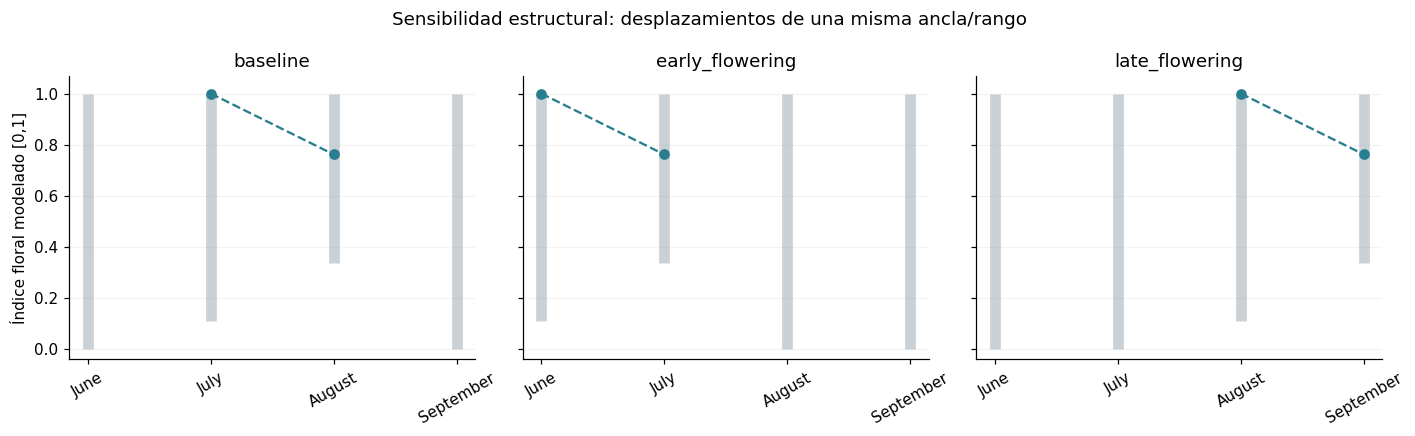

In [12]:
def shifted_profile(base, scenario, shift_months):
    source = base.set_index("month_number")
    rows = []
    for month in MONTH_NUMBERS:
        source_month = month - shift_months
        destination = source.loc[month]
        row = {"scenario": scenario, "year": YEAR, "month_number": month, "month": MONTH_NAMES[month],
               "shift_months": shift_months, "factor_source_month_number": source_month,
               "is_directly_observed_period": bool(destination.is_directly_observed_period),
               "monthly_observation_sufficient": bool(destination.monthly_observation_sufficient),
               "factor_is_observed": False, "source_outside_season": source_month not in source.index}
        if source_month in source.index:
            src = source.loc[source_month]
            row.update({"floral_factor": src.floral_factor, "floral_factor_lower": src.floral_factor_lower,
                        "floral_factor_upper": src.floral_factor_upper, "factor_status": src.factor_status,
                        "interval_kind": src.interval_kind, "source_evidence_level": src.evidence_level,
                        "evidence_level": src.evidence_level if shift_months == 0 else "modeled_shift_of_" + src.evidence_level,
                        "derivation_method": src.derivation_method if shift_months == 0 else f"Shift {shift_months:+d} month(s) from month {source_month}; source proxy/range retained"})
        else:
            row.update({"floral_factor": np.nan, "floral_factor_lower": 0.0, "floral_factor_upper": 1.0,
                        "factor_status": "unidentified_range_only", "interval_kind": "outside_season_unidentified_domain_not_CI",
                        "source_evidence_level": "outside_defined_season", "evidence_level": "modeled_shift_boundary_unidentified",
                        "derivation_method": "Source month outside June–September; no extrapolation, midpoint or cyclic wrap"})
        rows.append(row)
    return pd.DataFrame(rows)

SCENARIO_SHIFTS = {"baseline": 0, "early_flowering": -1, "late_flowering": 1}
temporal_scenarios = pd.concat([shifted_profile(profile, name, shift) for name, shift in SCENARIO_SHIFTS.items()], ignore_index=True)
display(temporal_scenarios[["scenario", "month", "factor_source_month_number", "floral_factor", "floral_factor_lower", "floral_factor_upper", "evidence_level"]])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, group) in zip(axes, temporal_scenarios.groupby("scenario", sort=False)):
    ax.vlines(range(4), group.floral_factor_lower, group.floral_factor_upper, color="#94A5B0", lw=7, alpha=.5)
    ax.plot(range(4), group.floral_factor, "o--", color="#287D8E")
    ax.set_xticks(range(4), group.month, rotation=30)
    ax.set(title=name, ylim=(-.04, 1.07))
    ax.grid(axis="y", alpha=.15)
axes[0].set_ylabel("Índice floral modelado [0,1]")
fig.suptitle("Sensibilidad estructural: desplazamientos de una misma ancla/rango")
fig.tight_layout()
plt.show()

## 12. Validaciones y archivos de salida
Se comprueban el rango de puntos existentes y límites, ausencia de negativos, cuatro meses, IDs y columnas espaciales conservadas, semilla, desplazamientos sin retorno circular y consistencia del baseline. Los puntos ausentes de meses no identificados son intencionales y se comprueban junto con sus límites; **no deben rellenarse silenciosamente en validación o simulación**.

Se exportan únicamente las dos tablas temporales solicitadas. Las escrituras son atómicas por archivo; se releen y se verifican los conteos y valores. No se escriben los archivos de entrada ni los notebooks posteriores.

In [13]:
def check_factors(frame, point, lower, upper):
    for col in [point, lower, upper]:
        values = frame[col].dropna()
        assert np.isfinite(values).all() and values.between(0, 1).all(), col
    assert frame[[lower, upper]].notna().all().all()
    assert frame[lower].le(frame[upper]).all()
    known = frame[point].notna()
    assert frame.loc[known, lower].le(frame.loc[known, point]).all()
    assert frame.loc[known, point].le(frame.loc[known, upper]).all()

check_factors(profile, "floral_factor", "floral_factor_lower", "floral_factor_upper")
check_factors(temporal_patches, "seasonal_floral_factor", "seasonal_floral_factor_lower", "seasonal_floral_factor_upper")
check_factors(temporal_scenarios, "floral_factor", "floral_factor_lower", "floral_factor_upper")
check_factors(stochastic_example, "effective_resource_factor", "effective_lower", "effective_upper")
assert (temporal_patches.month_number.isin(MONTH_NUMBERS)).all()
assert set(temporal_patches.month_number) == set(MONTH_NUMBERS)
assert len(temporal_patches) == len(spatial) * 4
assert not temporal_patches.duplicated(["patch_id", "month_number"]).any()
assert temporal_patches.groupby("month_number").patch_id.nunique().eq(len(spatial)).all()
assert set(temporal_patches.patch_id) == set(spatial.patch_id)
for month, group in temporal_patches.groupby("month_number"):
    pd.testing.assert_frame_equal(group[spatial.columns].reset_index(drop=True), spatial, check_exact=True)
assert not profile.factor_is_observed.any()
assert profile.loc[profile.month_number.isin([6, 9]), "floral_factor"].isna().all()
assert np.array_equal(variation, temporal_noise(len(profile), seed=SEED))
assert np.all(temporal_noise(4, seed=SEED, sigma=0) == 1)
if NOISE_SIGMA > 0:
    assert not np.array_equal(variation, temporal_noise(len(profile), seed=SEED + 1))
assert (variation > 0).all()
assert np.isclose(np.exp(-NOISE_SIGMA ** 2 / 2 + NOISE_SIGMA ** 2 / 2), 1)
assert len(temporal_scenarios) == 12 and not temporal_scenarios.duplicated(["scenario", "month_number"]).any()
for name, shift in SCENARIO_SHIFTS.items():
    scenario = temporal_scenarios.loc[temporal_scenarios.scenario.eq(name)].set_index("month_number")
    for month in MONTH_NUMBERS:
        source_month = month - shift
        row = scenario.loc[month]
        assert row.factor_source_month_number == source_month
        if source_month in MONTH_NUMBERS:
            src = profile.set_index("month_number").loc[source_month]
            assert np.allclose([row.floral_factor, row.floral_factor_lower, row.floral_factor_upper],
                               [src.floral_factor, src.floral_factor_lower, src.floral_factor_upper], equal_nan=True)
        else:
            assert pd.isna(row.floral_factor) and row.floral_factor_lower == 0 and row.floral_factor_upper == 1
            assert row.source_outside_season
baseline = temporal_scenarios.loc[temporal_scenarios.scenario.eq("baseline")]
assert np.allclose(baseline.floral_factor, profile.floral_factor, equal_nan=True)

def write_csv_atomic(frame, path):
    temp = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temp, index=False, encoding="utf-8", lineterminator="\n", date_format="%Y-%m-%d", na_rep="")
    temp.replace(path)

patches_path, scenarios_path = OUT / "temporal_patches.csv", OUT / "temporal_scenarios.csv"
write_csv_atomic(temporal_patches, patches_path)
write_csv_atomic(temporal_scenarios, scenarios_path)
patches_check, scenarios_check = pd.read_csv(patches_path), pd.read_csv(scenarios_path)
assert len(patches_check) == len(temporal_patches) and len(scenarios_check) == 12
assert set(patches_check.patch_id) == set(spatial.patch_id)
assert patches_check.groupby("month_number").patch_id.nunique().eq(len(spatial)).all()
for exported, original, column in [(patches_check, temporal_patches, "seasonal_floral_factor"),
                                    (scenarios_check, temporal_scenarios, "floral_factor")]:
    for suffix in ["", "_lower", "_upper"]:
        assert np.allclose(exported[column + suffix], original[column + suffix], equal_nan=True)
    check_factors(exported, column, column + "_lower", column + "_upper")
assert all(hashlib.sha256((ROOT / row.ruta).read_bytes()).hexdigest() == row.sha256
           for row in input_fingerprints.itertuples(index=False))
display(pd.DataFrame([{"archivo": str(p.relative_to(ROOT)), "filas": rows, "bytes": p.stat().st_size,
                       "sha256": hashlib.sha256(p.read_bytes()).hexdigest()}
                      for p, rows in [(patches_path, len(temporal_patches)), (scenarios_path, len(temporal_scenarios))]]))
print("Validaciones completas; entradas intactas y tablas temporales guardadas.")

,archivo,filas,bytes,sha256
0,data\project2\processed\temporal_patches.csv,2948,2084389,4e3d8667ac131cfd6852aede9e98775c95eda9420f388e6357caab3d1ca9ec86
1,data\project2\processed\temporal_scenarios.csv,12,3955,b3405b4494762b29dff5c4ebaef7ae41540fb79a770875c0537fe36cbdebb3d5


Validaciones completas; entradas intactas y tablas temporales guardadas.


## 13. Conclusiones para el modelo temporal
**Parte observada directamente:** conteos florales, dimensiones, individuos, horarios y clima presentes durante la ventana Dryad. La densidad por m² y las tasas por minuto son derivaciones de esas mediciones. El año de las fechas parciales es contextualizado, no escrito en cada fila original. No se tienen observaciones florales repetidas de los mismos sitios a lo largo de la temporada.

**Parte modelada:** temporada y resolución mensual, índice normalizado/saturado, proyección de sus límites generales a todos los parches, perturbación lognormal demostrativa y desplazamientos early/late. Los dos archivos no identifican una curva fenológica completa. Las diferencias entre julio y agosto no separan tiempo de localización, composición o esfuerzo. Los límites muestrales tampoco resuelven ese sesgo.

**Respaldo e incertidumbre:** julio tiene más días y sitios; agosto solo cubre una parte inicial. Junio y septiembre cuentan con contexto estacional externo, pero no con cantidades identificadas: quedan puntos ausentes y rangos [0,1]. No se consideran meses enteros observados. El clima ofrece asociaciones exploratorias con muestras desiguales, sin causalidad ni corrección climática automática del recurso.

In [14]:
display(temporal_summary)
display(profile[["month", "floral_factor", "floral_factor_lower", "floral_factor_upper", "factor_status"]])
print("Traps florales repetidos en fechas diferentes:", int(visits_per_site.gt(1).sum()))
print("Sesiones candidatas de actividad:", len(sessions))
print("Filas de temporal_patches.csv:", len(temporal_patches), "| IDs por mes:", len(spatial))
print("Filas de temporal_scenarios.csv:", len(temporal_scenarios))

,dataset,fecha_min,fecha_max,dias_unicos,registros,traps_unicos,registros_fechados,fechas_ausentes_invalidas,registros_año_contextualizado
0,flora,2017-07-18,2017-08-04,12,593,100,593,0,577
1,visitas,2017-07-18,2017-08-10,20,1297,101,1296,1,0


,month,floral_factor,floral_factor_lower,floral_factor_upper,factor_status
0,June,NaN,0.000000,1.0,unidentified_range_only
1,July,1.000000,0.108889,1.0,modeled_sample_proxy
2,August,0.761111,0.334444,1.0,modeled_sample_proxy
3,September,NaN,0.000000,1.0,unidentified_range_only


Traps florales repetidos en fechas diferentes: 0
Sesiones candidatas de actividad: 218
Filas de temporal_patches.csv: 2948 | IDs por mes: 737
Filas de temporal_scenarios.csv: 12


**Integración posterior:** el factor general puede modular una futura oferta relativa una vez justificada; todavía no es una capacidad floral absoluta. Las distancias vendrán del paisaje métrico, y las restricciones espaciales se conservan. Competencia, agotamiento, accesibilidad, preferencia y selección de parches necesitan módulos y parámetros posteriores; aquí no se implementan ni se infieren de correlaciones.

**Para `04_validation.ipynb`:** quedan `temporal_patches.csv` (un registro por parche y mes, restricciones, factores/rangos y evidencia) y `temporal_scenarios.csv` (baseline y dos desplazamientos trazables). La validación debe reconocer la falta de puntos en meses no identificados, comprobar la sensibilidad a los supuestos de año, duplicados, referencia, agregación y límites, y evitar tratar el indicador como disponibilidad real medida. No se ejecutaron competencia, agotamiento completo, selección probabilística, RANDOM, GREEDY, NSGA-II ni dashboard.